In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [2]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\Asus\OneDrive\Documents\DA_Project\Sample - Superstore.csv",
    encoding="latin1"
)

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
#Check rows and Columns
print(df.shape)
#Check Columns
print(df.columns)
#check datatypes
print(df.info())
#statistical summary
print(df.describe())

(9994, 21)
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 


In [4]:
print("Unique Customers:", df["Customer ID"].nunique())

print("Unique Products:", df["Product ID"].nunique())

print("Unique Orders:", df["Order ID"].nunique())

print("Categories:", df["Category"].unique())

print("Regions:", df["Region"].unique())

Unique Customers: 793
Unique Products: 1862
Unique Orders: 5009
Categories: ['Furniture' 'Office Supplies' 'Technology']
Regions: ['South' 'West' 'Central' 'East']


In [5]:
#Find Missing Values
missing_values = df.isnull().sum()

print(missing_values)

# missing values Percentage
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_report

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


,Missing_Count,Missing_Percentage
Row ID,0,0.0
Order ID,0,0.0
Order Date,0,0.0
Ship Date,0,0.0
Ship Mode,0,0.0
Customer ID,0,0.0
Customer Name,0,0.0
Segment,0,0.0
Country,0,0.0
City,0,0.0


In [6]:
# Duplicated Records 
total_duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", total_duplicates)

Total Duplicate Rows: 0


In [7]:
print(df.dtypes)

Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


In [8]:
# Statistical Numerical Columns
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [9]:
# Statistical Categorical Columns
df.describe(include="object")

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name
count,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994
unique,5009,1237,1334,4,793,793,3,1,531,49,4,1862,3,17,1850
top,CA-2017-100111,9/5/2016,12/16/2015,Standard Class,WB-21850,William Brown,Consumer,United States,New York City,California,West,OFF-PA-10001970,Office Supplies,Binders,Staple envelope
freq,14,38,35,5968,37,37,5191,9994,915,2001,3203,19,6026,1523,48


In [10]:
df.dtypes

Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [11]:
# Convert  Data Types 
# Convert date columns into datetime format
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    errors="coerce"
)

# Convert text columns from object to string
text_columns = df.select_dtypes(include="object").columns

df[text_columns] = df[text_columns].astype("str")

# Check updated data types
df.dtypes

Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code               int64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

In [12]:
# Unusal Values 
print("Negative Sales:", (df["Sales"] < 0).sum())

print("Zero or Negative Quantity:", (df["Quantity"] <= 0).sum())

print(
    "Discount Outside 0 to 1:",
    ((df["Discount"] < 0) | (df["Discount"] > 1)).sum()
)

print("Negative Profit:", (df["Profit"] < 0).sum())

Negative Sales: 0
Zero or Negative Quantity: 0
Discount Outside 0 to 1: 0
Negative Profit: 1871


In [13]:
validation_df = df.copy()

validation_df["Order Date"] = pd.to_datetime(
    validation_df["Order Date"],
    errors="coerce"
)

validation_df["Ship Date"] = pd.to_datetime(
    validation_df["Ship Date"],
    errors="coerce"
)

In [14]:
# Check invalid dates and Ship dates
print(
    "Invalid Order Dates:",
    validation_df["Order Date"].isna().sum()
)

print(
    "Invalid Ship Dates:",
    validation_df["Ship Date"].isna().sum()
)

print(
    "Ship Date Before Order Date:",
    (
        validation_df["Ship Date"]
        < validation_df["Order Date"]
    ).sum()
)

Invalid Order Dates: 0
Invalid Ship Dates: 0
Ship Date Before Order Date: 0


In [15]:
# Check numerical values and Categorical values
# Numerical columns
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

# Date columns
date_columns = df.select_dtypes(
    include=["datetime"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

print("\nDate Columns:")
print(date_columns)

Numerical Columns:
['Row ID', 'Postal Code', 'Sales', 'Quantity', 'Discount', 'Profit']

Categorical Columns:
['Order ID', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name']

Date Columns:
['Order Date', 'Ship Date']


In [16]:
df[['Order Date','Ship Date']].head(10)

,Order Date,Ship Date
0,2016-11-08,2016-11-11
1,2016-11-08,2016-11-11
2,2016-06-12,2016-06-16
3,2015-10-11,2015-10-18
4,2015-10-11,2015-10-18
5,2014-06-09,2014-06-14
6,2014-06-09,2014-06-14
7,2014-06-09,2014-06-14
8,2014-06-09,2014-06-14
9,2014-06-09,2014-06-14


In [17]:
# Create a working copy of the original dataset
df_cleaned = df.copy()



In [18]:
# Remove exact duplicate rows
df_cleaned = df_cleaned.drop_duplicates()

# Convert date columns
df_cleaned["Order Date"] = pd.to_datetime(
    df_cleaned["Order Date"], errors="coerce"
)

df_cleaned["Ship Date"] = pd.to_datetime(
    df_cleaned["Ship Date"], errors="coerce"
)

# print("Basic cleaning completed!")

In [19]:
# Data Cleaning with justified Decisions
cleaning_log = pd.DataFrame([
    {
        "Issue": "Exact duplicate records",
        "Action Taken": "Removed confirmed exact duplicate rows",
        "Justification": "To avoid counting identical records more than once"
    },
    {
        "Issue": "Order Date and Ship Date data types",
        "Action Taken": "Converted to datetime",
        "Justification": "Required for date analysis and shipping duration calculations"
    },
    {
        "Issue": "Text column data types",
        "Action Taken": "Converted object columns to string",
        "Justification": "To maintain consistent text data types"
    },
    {
        "Issue": "Negative Profit",
        "Action Taken": "Retained negative values",
        "Justification": "Negative profit represents a valid business loss"
    },
    {
        "Issue": "Missing values",
        "Action Taken": "Pending inspection",
        "Justification": "Treatment depends on the column and business meaning"
    },
    {
        "Issue": "Unusual numerical and date values",
        "Action Taken": "Pending investigation",
        "Justification": "Values must be checked before correction or removal"
    }
])

cleaning_log

,Issue,Action Taken,Justification
0,Exact duplicate records,Removed confirmed exact duplicate rows,To avoid counting identical records more than ...
1,Order Date and Ship Date data types,Converted to datetime,Required for date analysis and shipping durati...
2,Text column data types,Converted object columns to string,To maintain consistent text data types
3,Negative Profit,Retained negative values,Negative profit represents a valid business loss
4,Missing values,Pending inspection,Treatment depends on the column and business m...
5,Unusual numerical and date values,Pending investigation,Values must be checked before correction or re...


In [20]:
# Compare original and cleaned Dataset
print("Original Rows:", len(df))
print("Cleaned Rows:", len(df_cleaned))

print("Original Columns:", len(df.columns))
print("Cleaned Columns:", len(df_cleaned.columns))

print("Remaining Exact Duplicates:",
      df_cleaned.duplicated().sum())

print("Remaining Missing Values:",
      df_cleaned.isnull().sum().sum())

Original Rows: 9994
Cleaned Rows: 9994
Original Columns: 21
Cleaned Columns: 21
Remaining Exact Duplicates: 0
Remaining Missing Values: 0


## EDA

In [21]:
# Display first five records
df_cleaned.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [22]:

df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

In [23]:

df_cleaned.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [24]:
print("Original Shape:", df.shape)

print("Cleaned Shape:", df_cleaned.shape)

Original Shape: (9994, 21)
Cleaned Shape: (9994, 21)


In [25]:
# Calculate total sales
total_sales = df_cleaned['Sales'].sum()

print("Total Sales:", total_sales)

Total Sales: 2297200.8603


In [26]:
# Calculate total Profit
total_profit = df_cleaned['Profit'].sum()

print("Total Profit:", total_profit)

Total Profit: 286397.0217


In [27]:
# Calculate total Quantity
total_quantity = df_cleaned['Quantity'].sum()

print("Total Quantity:", total_quantity)

Total Quantity: 37873


In [28]:
# Calculate total orders
total_Orders = df_cleaned['Order ID'].nunique()

print("Total Orders:", total_Orders)

Total Orders: 5009


In [29]:
# Calculate total Customers
total_Customers = df_cleaned['Customer ID'].nunique()

print("Total Custumers:", total_Customers)

Total Custumers: 793


In [30]:
# Calculate total Products
total_Products = df_cleaned['Product ID'].nunique()

print("Total Products:", total_Products)

Total Products: 1862


In [31]:
# Calculate average sales
average_sales = df_cleaned['Sales'].mean()

print("Average Sales:", average_sales)

Average Sales: 229.85800083049827


In [ ]:

print("Minimum Sales:", df_cleaned['Sales'].min())

print("Maximum Sales:", df_cleaned['Sales'].max())

Minimum Sales: 0.444
Maximum Sales: 22638.48


In [33]:
sales_summary = df_cleaned['Sales'].agg([
    'sum',
    'mean',
    'min',
    'max',
    'count'
])

sales_summary

sum      2.297201e+06
mean     2.298580e+02
min      4.440000e-01
max      2.263848e+04
count    9.994000e+03
Name: Sales, dtype: float64

In [34]:
# Calculate average Profit
average_Profit = df_cleaned['Profit'].mean()

print("Average Profit:", average_Profit)

Average Profit: 28.65689630778467


In [ ]:
#Ternary Operator using
# 
profit_margin = (
    total_profit / total_sales
) * 100 if total_sales != 0 else np.nan

print("Profit Margin:", profit_margin)

Profit Margin: 12.467217240315605


In [36]:
kpi_report = pd.DataFrame({
    'KPI': [
        'Total Sales',
        'Total Profit',
        'Total Quantity',
        'Total Customers',
        'Total Orders',
        'Profit Margin'
        
    ],

    'Value': [
        total_sales,
        total_profit,
        profit_margin,
        total_quantity,
        total_Customers,
        total_Orders
    ]
})

kpi_report
kpi_report.style.format({
    'Value': '{:,.2f}'
})

,KPI,Value
0,Total Sales,"2,297,200.86"
1,Total Profit,"286,397.02"
2,Total Quantity,12.47
3,Total Customers,"37,873.00"
4,Total Orders,793.00
5,Profit Margin,"5,009.00"


In [37]:
df['Order Date'].dtype
df_cleaned['Order Date'].head()

0   2016-11-08
1   2016-11-08
2   2016-06-12
3   2015-10-11
4   2015-10-11
Name: Order Date, dtype: datetime64[ns]

In [ ]:
# Category Wise group sales
# After group by Arrange order by ASC or DESc
category_sales = (
    df_cleaned.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

category_sales

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64

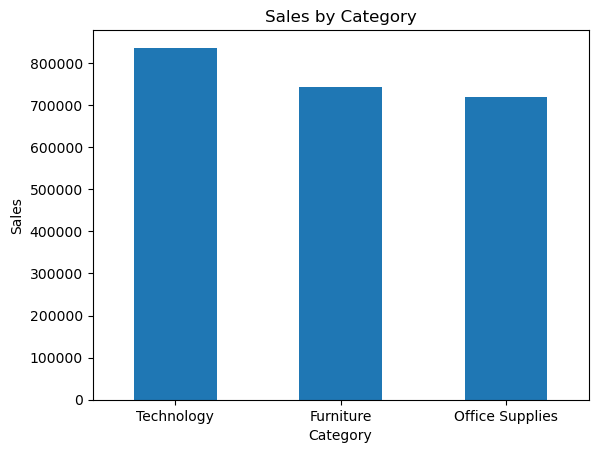

In [39]:
category_sales.plot(
    kind="bar",
    title="Sales by Category",
    xlabel="Category",
    ylabel="Sales"
)

plt.xticks(rotation=0)
plt.show()

In [40]:
category_profit = (
    df_cleaned.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

category_profit

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64

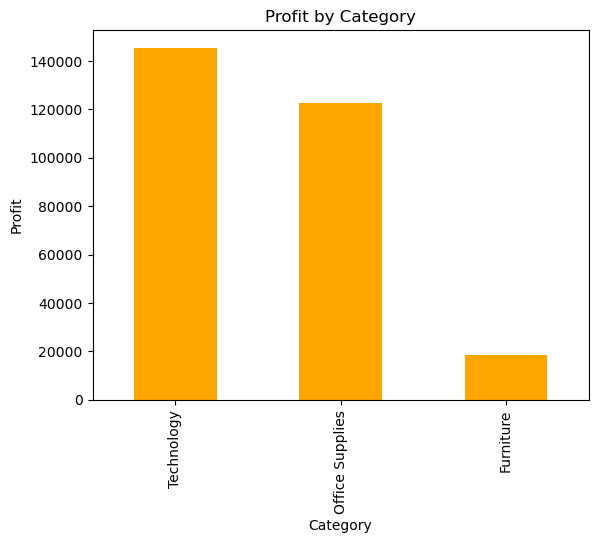

In [41]:
category_profit.plot(
    kind="bar",
    title="Profit by Category",
    color="orange"
)

plt.ylabel("Profit")
plt.show()

In [42]:
subcategory_analysis = (
    df_cleaned.groupby("Sub-Category")
    .agg({
        "Sales": "sum",
        "Profit": "sum",
        "Quantity": "sum"
    })
    .sort_values("Sales", ascending=False)
)

subcategory_analysis

,Sales,Profit,Quantity
Sub-Category,,,
Phones,330007.0540,44515.7306,3289
Chairs,328449.1030,26590.1663,2356
Storage,223843.6080,21278.8264,3158
Tables,206965.5320,-17725.4811,1241
Binders,203412.7330,30221.7633,5974
Machines,189238.6310,3384.7569,440
Accessories,167380.3180,41936.6357,2976
Copiers,149528.0300,55617.8249,234
Bookcases,114879.9963,-3472.5560,868


In [43]:
subcategory_analysis.head(5)

,Sales,Profit,Quantity
Sub-Category,,,
Phones,330007.054,44515.7306,3289
Chairs,328449.103,26590.1663,2356
Storage,223843.608,21278.8264,3158
Tables,206965.532,-17725.4811,1241
Binders,203412.733,30221.7633,5974


In [44]:
subcategory_analysis.sort_values(
    "Profit"
).head(5)

,Sales,Profit,Quantity
Sub-Category,,,
Tables,206965.5320,-17725.4811,1241
Bookcases,114879.9963,-3472.5560,868
Supplies,46673.5380,-1189.0995,647
Fasteners,3024.2800,949.5182,914
Machines,189238.6310,3384.7569,440


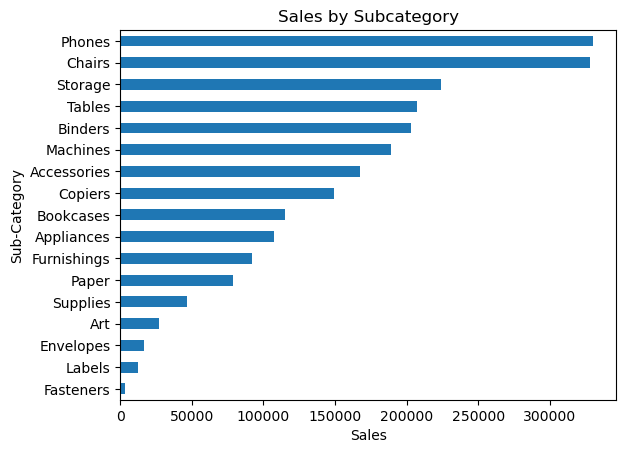

In [45]:
subcategory_analysis["Sales"].sort_values().plot(
    kind="barh",
    title="Sales by Subcategory"
)

plt.xlabel("Sales")
plt.show()

In [46]:
region_analysis = (
    df_cleaned.groupby("Region")
    .agg({
        "Sales": "sum",
        "Profit": "sum",
        "Quantity": "sum",
        "Order ID": "nunique"
    })
    .rename(columns={
        "Order ID": "Total Orders"
    })
)

region_analysis

,Sales,Profit,Quantity,Total Orders
Region,,,,
Central,501239.8908,39706.3625,8780,1175
East,678781.2400,91522.7800,10618,1401
South,391721.9050,46749.4303,6209,822
West,725457.8245,108418.4489,12266,1611


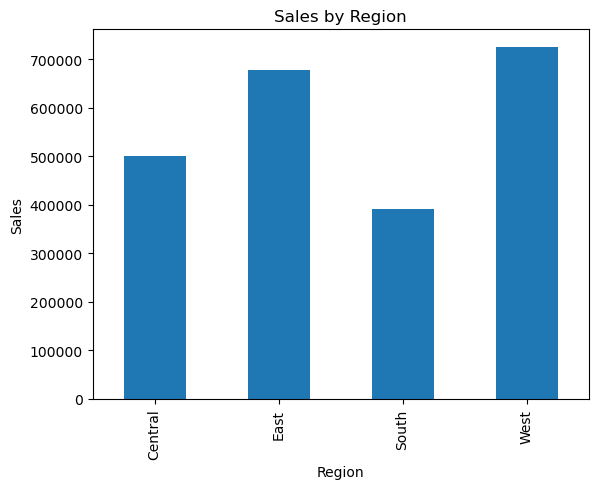

In [47]:
region_analysis["Sales"].plot(
    kind="bar",
    title="Sales by Region"
)

plt.ylabel("Sales")
plt.show()

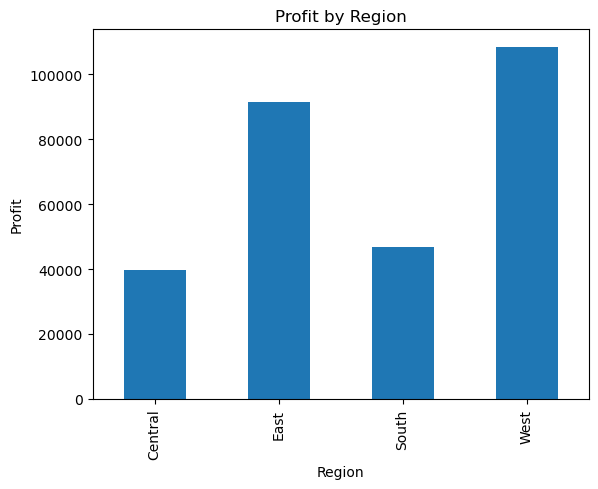

In [48]:
region_analysis["Profit"].plot(
    kind="bar",
    title="Profit by Region"
)

plt.ylabel("Profit")
plt.show()

In [49]:
# Analyze each customer segment by calculating total sales, total profit, unique customers, and unique orders.
segment_analysis = (
    df_cleaned.groupby("Segment")
    .agg({
        "Sales": "sum",
        "Profit": "sum",
        "Customer ID": "nunique",
        "Order ID": "nunique"
    })
    .rename(columns={
        "Customer ID": "Customers",
        "Order ID": "Orders"
    })
)

segment_analysis

,Sales,Profit,Customers,Orders
Segment,,,,
Consumer,1.161401e+06,134119.2092,409,2586
Corporate,7.061464e+05,91979.1340,236,1514
Home Office,4.296531e+05,60298.6785,148,909


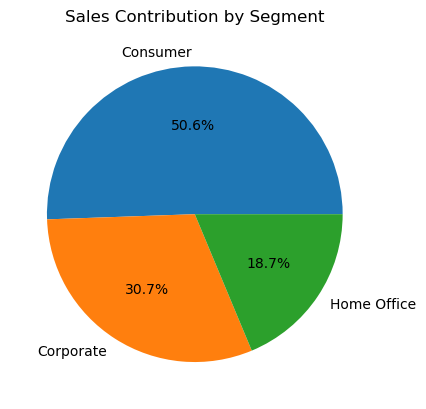

In [50]:
segment_analysis["Sales"].plot(
    kind="pie",
    autopct="%1.1f%%",
    title="Sales Contribution by Segment"
)

plt.ylabel("")
plt.show()

In [51]:
df_cleaned["Year"] = df_cleaned["Order Date"].dt.year

df_cleaned["Month"] = df_cleaned["Order Date"].dt.month

df_cleaned["Month_Name"] = (
    df_cleaned["Order Date"].dt.month_name()
)

In [52]:
# Monthly Sales
df_cleaned['Month'] = (
    df_cleaned['Order Date'].dt.to_period('M')
)

monthly_sales = df_cleaned.groupby('Month')['Sales'].sum()

monthly_sales

Month
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160
2017-

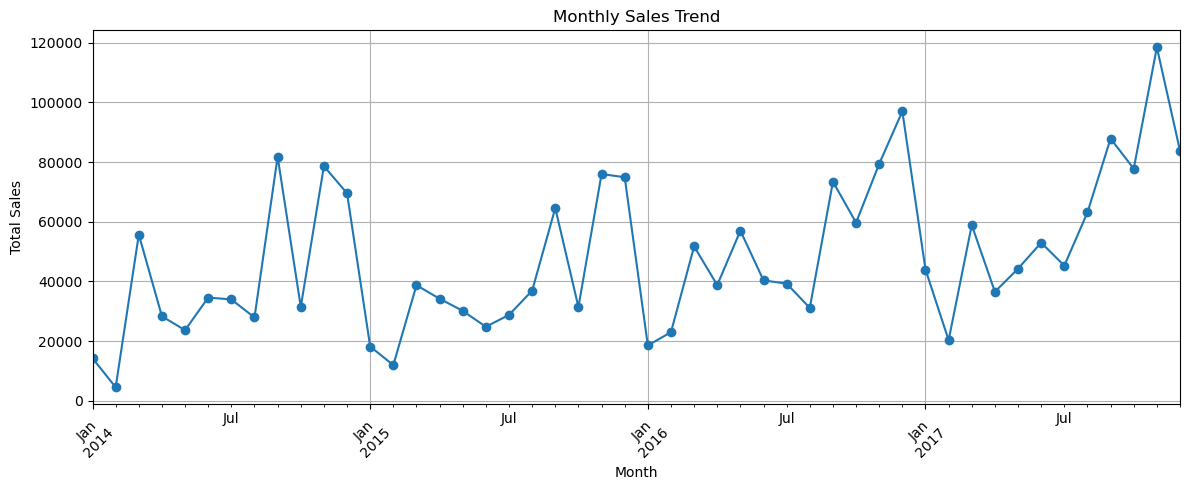

In [53]:
# Monthly Sales visualization
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [54]:
yearly_sales = (
    df_cleaned.groupby("Year")["Sales"]
    .sum()
)

yearly_sales

Year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64

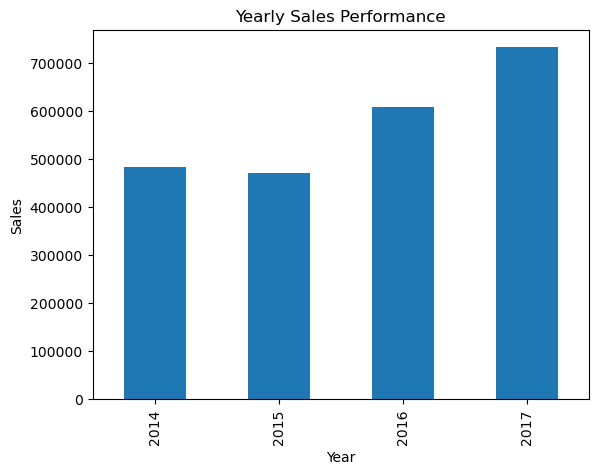

In [55]:
yearly_sales.plot(
    kind="bar",
    title="Yearly Sales Performance"
)

plt.ylabel("Sales")
plt.show()

In [56]:
top_customers = (
    df_cleaned.groupby("Customer Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64

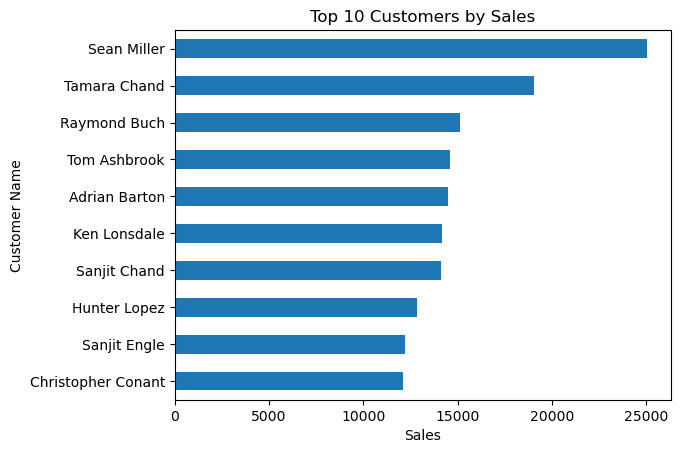

In [57]:
top_customers.sort_values().plot(
    kind="barh",
    title="Top 10 Customers by Sales"
)

plt.xlabel("Sales")
plt.show()

In [58]:
top_products = (
    df_cleaned.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

In [59]:
top_products = (
    df_cleaned.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

In [60]:
top_products = (
    df_cleaned.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

In [61]:
discount_profit_corr = df_cleaned[
    ["Discount", "Profit"]
].corr()

discount_profit_corr

,Discount,Profit
Discount,1.000000,-0.219487
Profit,-0.219487,1.000000


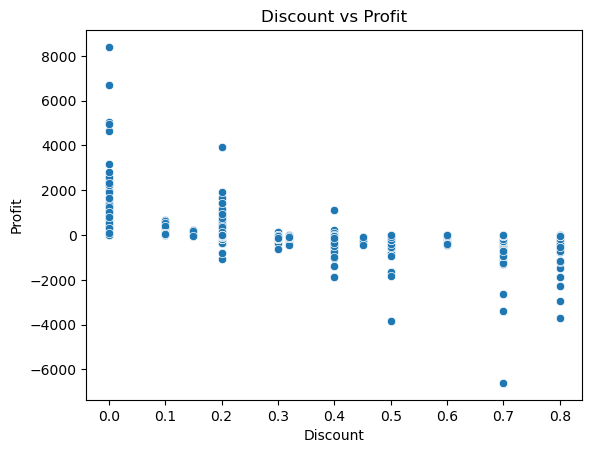

In [62]:
sns.scatterplot(
    data=df_cleaned,
    x="Discount",
    y="Profit"
)

plt.title("Discount vs Profit")
plt.show()

In [63]:
discount_analysis = (
    df_cleaned.groupby("Discount")
    .agg({
        "Sales": "sum",
        "Profit": "sum",
        "Order ID": "nunique"
    })
)
pd.set_option('display.float_format', '{:.2f}'.format)

# kpi_report

discount_analysis

,Sales,Profit,Order ID
Discount,,,
0.00,1087908.47,320987.60,2644
0.10,54369.35,9029.18,89
0.15,27558.52,1418.99,51
0.20,764594.37,90337.31,2407
0.30,103226.65,-10369.28,211
0.32,14493.46,-2391.14,27
0.40,116417.78,-23057.05,185
0.45,5484.97,-2493.11,10
0.50,58918.54,-20506.43,64


In [64]:
df_cleaned["Shipping Days"] = (
    df_cleaned["Ship Date"] -
    df_cleaned["Order Date"]
).dt.days

In [65]:
shipping_analysis = (
    df_cleaned.groupby("Ship Mode")
    .agg({
        "Shipping Days": "mean",
        "Order ID": "nunique",
        "Sales": "sum"
    })
    .rename(columns={
        "Order ID": "Total Orders",
        "Shipping Days": "Average Shipping Days"
    })
)

shipping_analysis

,Average Shipping Days,Total Orders,Sales
Ship Mode,,,
First Class,2.18,787,351428.42
Same Day,0.04,264,128363.12
Second Class,3.24,964,459193.57
Standard Class,5.01,2994,1358215.74


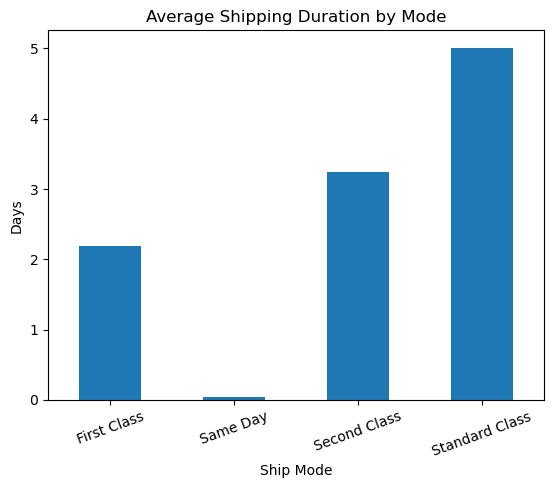

In [66]:
shipping_analysis["Average Shipping Days"].plot(
    kind="bar",
    title="Average Shipping Duration by Mode"
)

plt.ylabel("Days")
plt.xticks(rotation=20)
plt.show()

In [67]:
os.makedirs("../processed_data", exist_ok=True)

df_cleaned.to_csv(
    "../processed_data/cleaned_superstore.csv",
    index=False
)

In [68]:
os.makedirs("../reports", exist_ok=True)

category_analysis = (
    df_cleaned.groupby("Category")
    .agg({
        "Sales": "sum",
        "Profit": "sum",
        "Quantity": "sum"
    })
)
category_analysis

# category_analysis.to_csv(
#     "../reports/category_analysis.csv"
# )

,Sales,Profit,Quantity
Category,,,
Furniture,741999.80,18451.27,8028
Office Supplies,719047.03,122490.80,22906
Technology,836154.03,145454.95,6939


In [69]:
import os

os.makedirs("../Reports", exist_ok=True)

In [70]:
region_analysis.to_csv(
    "../Reports/region_analysis.csv"
)

In [71]:
import os

report_dir = r"C:\Users\Asus\OneDrive\Documents\DA_Project\data\Reports"

os.makedirs(report_dir, exist_ok=True)

region_analysis.to_csv(
    os.path.join(report_dir, "region_analysis.csv"),
    index=True
)

print("Region report saved successfully!")

Region report saved successfully!


In [72]:
reports = {
    "region_analysis": region_analysis,
    "category_analysis": category_analysis,
    "subcategory_analysis": subcategory_analysis,
    "segment_analysis": segment_analysis,
    "kpi_report": kpi_report
}

for name, data in reports.items():
    data.to_csv(
        os.path.join(report_dir, f"{name}.csv")
    )

print("All reports saved successfully!")

All reports saved successfully!


In [73]:
segment_analysis.to_csv(
    "../Reports/segment_analysis.csv"
)

In [74]:
kpi_report.to_csv(
    "../Reports/kpi_report.csv",
    index=False
)

In [75]:
import os

print("Notebook Working Directory:")
print(os.getcwd())

print("\nFiles and Folders:")
print(os.listdir())

Notebook Working Directory:
c:\Users\Asus\OneDrive\Documents\DA_Project

Files and Folders:
['data', 'Sales_Analysis-.ipynb', 'Sample - Superstore.csv']


In [76]:
import os

print(os.getcwd())

c:\Users\Asus\OneDrive\Documents\DA_Project
